In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import yfinance as yf

In [2]:
w_df = pd.read_csv("Best Risk_adjusted Weights")
risk_df = pd.read_csv("Risk Cont")

In [3]:
w_df[["Minimum Volatility", "Maximum Sharpe"]] = w_df[["Minimum Volatility", "Maximum Sharpe"]]/100
w_df

,Ticker,Minimum Volatility,Maximum Sharpe
0,AAPL,8.151856e-02,1.689728e-01
1,AVGO,5.194301e-02,2.954422e-17
2,BE,1.387779e-17,1.533252e-02
3,CVS,8.253266e-02,9.010693e-02
4,ETN,4.986878e-02,0.000000e+00
5,GOOGL,7.043753e-02,4.193422e-18
6,GRID,5.893979e-02,0.000000e+00
7,JNJ,8.998466e-02,0.000000e+00
8,MSFT,7.174340e-02,1.256194e-01
9,NVDA,5.846690e-02,1.289229e-16


In [4]:
tickers = w_df["Ticker"].to_list()
tickers

['AAPL',
 'AVGO',
 'BE',
 'CVS',
 'ETN',
 'GOOGL',
 'GRID',
 'JNJ',
 'MSFT',
 'NVDA',
 'ORCL',
 'SMH',
 'VHT',
 'VOO',
 'VTI',
 'VXUS']

In [5]:

def S_data(ticker):
    data = yf.download(tickers, start = "2021-10-16", end = "", interval = "1d", progress = False, timeout = 30, auto_adjust = True)["Close"]
    return data.dropna()

stock_data = S_data(tickers)
stock_data

Ticker,AAPL,AVGO,BE,CVS,ETN,GOOGL,GRID,JNJ,MSFT,NVDA,ORCL,SMH,VHT,VOO,VTI,VXUS
Date,,,,,,,,,,,,,,,,
2021-10-18,142.940598,46.076965,21.270000,71.568993,149.235397,141.432175,92.187317,139.252716,294.914581,22.124554,90.199509,128.390427,229.109024,383.323334,216.025757,55.763512
2021-10-19,145.096237,46.720482,21.670000,71.916359,149.429779,141.886841,92.736382,142.513992,295.816711,22.192251,90.713554,129.860367,232.064651,386.306549,217.602295,56.209755
2021-10-20,145.583878,46.628941,20.910000,73.322655,151.021393,140.432693,93.209724,142.435745,295.029785,22.006069,90.321022,129.287918,234.936707,387.807526,218.451202,56.355648
2021-10-21,145.798477,47.064663,21.200001,74.012840,150.021988,140.548569,92.499710,142.105255,298.244873,22.592489,90.003258,130.762726,236.237854,388.758331,219.048248,56.020954
2021-10-22,145.027954,47.180004,20.190001,74.575211,150.262589,136.269806,92.783722,142.383560,296.709259,22.626341,91.825745,129.608093,236.721222,388.366791,218.628510,56.192589
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-12,340.970001,354.730011,262.279999,87.739998,426.690002,352.720001,178.699997,263.730011,541.150024,226.320007,137.389999,590.989990,320.670013,715.130005,381.570007,84.440002
2026-10-13,341.269989,357.309998,263.450012,87.550003,428.309998,353.779999,179.250000,248.610001,543.450012,228.520004,143.199997,588.119995,316.369995,715.200012,381.320007,84.540001
2026-10-14,342.959991,346.250000,239.339996,90.389999,408.850006,347.640015,174.479996,253.910004,533.690002,221.300003,130.550003,564.739990,323.149994,707.429993,376.880005,83.580002


In [6]:
market = ["QQQ", "SPY"]
def B_data(ticker):
    data = yf.download(ticker, start = "2021-10-16", end = "", interval = "1d", progress = False, timeout = 30, auto_adjust = True)["Close"]
    return data.dropna()

bench_data = B_data(market)
bench_data

Ticker,QQQ,SPY
Date,,
2021-10-18,361.676910,418.257874
2021-10-19,364.413818,421.484680
2021-10-20,363.938354,423.140198
2021-10-21,366.160858,424.243835
2021-10-22,363.084229,423.804291
...,...,...
2026-10-12,746.039978,778.099976
2026-10-13,743.570007,778.010010
2026-10-14,728.950012,769.599976


# 1. Simulating Returns and Properties (Rolling 10 Days)

In [7]:
weights = w_df[["Ticker","Maximum Sharpe"]].set_index("Ticker")
stock_ret = stock_data.pct_change().dropna()
portfolio = stock_ret @ weights

In [8]:
portfolio = portfolio.dropna().rename(columns = {"Maximum Sharpe": "Portfolio Daily Ret"})
portfolio

,Portfolio Daily Ret
Date,
2021-10-19,0.011263
2021-10-20,0.007322
2021-10-21,0.006548
2021-10-22,-0.001370
2021-10-25,0.006372
...,...
2026-10-12,0.004993
2026-10-13,-0.006694
2026-10-14,0.007267


In [9]:
rolling_10_days_ret = portfolio["Portfolio Daily Ret"].rolling(10).apply(lambda x: (1+x).prod() - 1)


portfolio_10day = pd.DataFrame({"10 Days Cumret": rolling_10_days_ret, "10 Days Vol": portfolio["Portfolio Daily Ret"].rolling(10).std()})
portfolio_10day

,10 Days Cumret,10 Days Vol
Date,,
2021-10-19,NaN,NaN
2021-10-20,NaN,NaN
2021-10-21,NaN,NaN
2021-10-22,NaN,NaN
2021-10-25,NaN,NaN
...,...,...
2026-10-12,0.007900,0.006144
2026-10-13,0.005281,0.006422
2026-10-14,0.017613,0.006423


In [10]:
# MARKET 
B_ret = bench_data.pct_change().dropna()
B_w  = pd.Series({"QQQ": 0.7, "SPY": 0.3})

Benchmark = pd.DataFrame(B_ret @ B_w).rename(columns = {0: "Benchmark Ret"})

Benchmark

,Benchmark Ret
Date,
2021-10-19,0.007612
2021-10-20,0.000265
2021-10-21,0.005057
2021-10-22,-0.006192
2021-10-25,0.008775
...,...
2026-10-12,-0.005054
2026-10-13,-0.002352
2026-10-14,-0.017006


In [11]:
rolling_10_days_ret_bench = Benchmark["Benchmark Ret"].rolling(10).apply(lambda x: (1+x).prod() - 1)

Bench_10_days = pd.DataFrame({"Bench 10 Days Cumret": rolling_10_days_ret_bench})
Bench_10_days.dropna(inplace = True)
Bench_10_days

,Bench 10 Days Cumret
Date,
2021-11-01,0.036391
2021-11-02,0.032821
2021-11-03,0.042111
2021-11-04,0.047637
2021-11-05,0.055966
...,...
2026-10-12,0.013950
2026-10-13,0.010779
2026-10-14,-0.007532


In [12]:
rf_rates_annual = 0.0533
rf_rates_daily = (1 + rf_rates_annual)**(1/252) - 1

portfolio_10day["Sharpe"] = ((portfolio["Portfolio Daily Ret"].rolling(10).mean() - rf_rates_daily) / portfolio["Portfolio Daily Ret"].rolling(10).std()) 
portfolio_10day.reset_index(inplace = True)

 # NOTE: THIS SHARPE RATIO IS ESSENTIALLY USING THE LAST 10 DAYS AS AN INPUT TO CALCULATE, JUST NORMAL SHARPE, NOT CUMMULATIVE

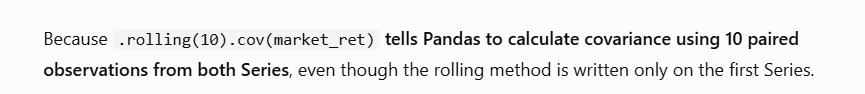

In [13]:
portfolio_10day.dropna(inplace = True)
portfolio_10day

,Date,10 Days Cumret,10 Days Vol,Sharpe
9,2021-11-01,0.056616,0.004780,1.114303
10,2021-11-02,0.052300,0.004393,1.118560
11,2021-11-03,0.056905,0.004837,1.106955
12,2021-11-04,0.048524,0.005293,0.860769
13,2021-11-05,0.046647,0.005547,0.789108
...,...,...,...,...
1249,2026-10-12,0.007900,0.006144,0.097355
1250,2026-10-13,0.005281,0.006422,0.052832
1251,2026-10-14,0.017613,0.006423,0.242858
1252,2026-10-15,0.036923,0.006152,0.559687


In [14]:
Market_portfolio_merge = portfolio.merge(Benchmark, on = "Date")
Beta = (Market_portfolio_merge["Portfolio Daily Ret"].rolling(10).cov(Market_portfolio_merge["Benchmark Ret"])) / Market_portfolio_merge["Benchmark Ret"].rolling(10).var()
Beta = pd.DataFrame(Beta)

In [15]:
portfolio_10day = portfolio_10day.merge(Beta, on = "Date").rename(columns = {0: "Beta"})
portfolio_10day

,Date,10 Days Cumret,10 Days Vol,Sharpe,Beta
0,2021-11-01,0.056616,0.004780,1.114303,0.792607
1,2021-11-02,0.052300,0.004393,1.118560,0.741705
2,2021-11-03,0.056905,0.004837,1.106955,0.871196
3,2021-11-04,0.048524,0.005293,0.860769,0.589575
4,2021-11-05,0.046647,0.005547,0.789108,0.782743
...,...,...,...,...,...
1240,2026-10-12,0.007900,0.006144,0.097355,0.399078
1241,2026-10-13,0.005281,0.006422,0.052832,0.453472
1242,2026-10-14,0.017613,0.006423,0.242858,0.093831
1243,2026-10-15,0.036923,0.006152,0.559687,0.163291


# Linear Regression

In [16]:
timesplit = pd.to_datetime("2025-01-01")

# TIME SPLIT
Test = portfolio_10day[portfolio_10day["Date"] <= timesplit]
Predict = portfolio_10day[portfolio_10day["Date"] > timesplit]

# DATA INCLUSION
data_req = portfolio_10day.copy().drop(columns = ["Date", "10 Days Cumret"])
model_data = data_req.columns.to_list()

model = LinearRegression()
model.fit(Test[model_data], Test["10 Days Cumret"])

Predict["Prediction"] = model.predict(Predict[model_data])

Predict["Residual"] = Predict["10 Days Cumret"] - Predict["Prediction"]
Predict

C:\Users\hotru\AppData\Local\Temp\ipykernel_41600\4254974037.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Predict["Prediction"] = model.predict(Predict[model_data])
C:\Users\hotru\AppData\Local\Temp\ipykernel_41600\4254974037.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Predict["Residual"] = Predict["10 Days Cumret"] - Predict["Prediction"]


,Date,10 Days Cumret,10 Days Vol,Sharpe,Beta,Prediction,Residual
796,2025-01-02,-0.024037,0.009863,-0.262822,0.649475,-0.021394,-0.002642
797,2025-01-03,0.006718,0.009128,0.054903,0.820737,0.005185,0.001532
798,2025-01-06,0.020504,0.008862,0.209999,0.785857,0.017230,0.003274
799,2025-01-07,0.004368,0.008123,0.031954,0.629530,0.002156,0.002212
800,2025-01-08,-0.000081,0.007827,-0.023843,0.622569,-0.002231,0.002149
...,...,...,...,...,...,...,...
1240,2026-10-12,0.007900,0.006144,0.097355,0.399078,0.006041,0.001859
1241,2026-10-13,0.005281,0.006422,0.052832,0.453472,0.002874,0.002407
1242,2026-10-14,0.017613,0.006423,0.242858,0.093831,0.015126,0.002487
1243,2026-10-15,0.036923,0.006152,0.559687,0.163291,0.040742,-0.003818


In [17]:
Predict["Residual"].describe()

count    449.000000
mean       0.000340
std        0.010036
min       -0.068982
25%       -0.002409
50%        0.002001
75%        0.004741
max        0.050681
Name: Residual, dtype: float64

# NEXT STEP: Gather Data on Macro events